In [ ]:
"""
Define of all the unit:
CGS system
P in units of eng * cm **-3
T_1 in unit of k
m in unit of g
rho in unit of g cm **-3
metallicity in units of solar metallicity
kB​=1.380649e−16 erg* K**-1
"""

'\nDefine of all the unit:\nCGS system\nP in units of eng * cm **-3\nT_1 in unit of k\nm in unit of g\nrho in unit of g cm **-3\nmetallicity in units of solar metallicity\nkB\u200b=1.380649e−16 erg* K**-1\n'

In [ ]:
"""
the number density is not clearly defined: n can be both total number densidty, and hydrogen number density
"""

'\nthe number density is not clearly defined: n can be both total number densidty, and hydrogen number density\n'

In [ ]:
"""
Define of all constant:

"""
mu = 0.62
muH = 1/0.75
kb = 1.380649e-16
gamma = 5/3
Z_solar = 0.02
mH = 1.673536 * 10**(-24)

In [ ]:
import numpy as np
def shock_tran(M_1, rho_1, T_1, m):
  # presrure and bulk velocity
  # m here is the average mass of the gases rho_tot = n_tot * m
  P_1 = rho_1* kb * T_1 /m
  u_1 = M_1 * (gamma * P_1 /rho_1)**.5 # M = u / v_sound
  # after shock density, tem, and bulk velocity
  rho_2 = rho_1 * ((gamma+1) * M_1**2)/((gamma - 1) * M_1**2 + 2)
  T_2 = ((gamma-1)* M_1** 2 + 2)*(2* gamma* M_1**2 - (gamma - 1))/((gamma + 1)**2 * M_1**2)*T_1
  u_2 = u_1 * rho_1/rho_2
  # return the ratio
  return u_1/u_2, rho_1/rho_2, T_2/T_1


In [ ]:
"""
test code
"""
rho_1 = mH* (mu) * 10**(-3.45)
T_1 = 10**(6.9)
M_1 = 4.8
u_r, rho_r, T_r = shock_tran(M_1, rho_1, T_1, mH* (mu))
print(u_r, 1/rho_r, T_r)

3.539170506912443 3.5391705069124426 8.066861979166664


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
M_1 = np.linspace(1, 10, 10000)
u_r, rho_r, T_r = shock_tran(M_1, rho_1, T_1, 1 * 10**-27)
print(rho_r[100])

0.8812495695595222


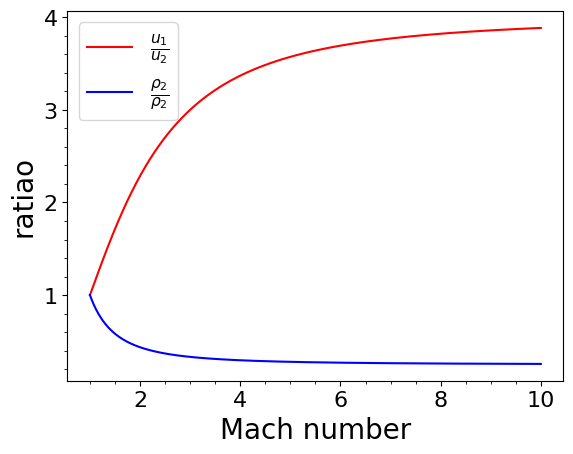

In [ ]:
"""
plot of ratio of u, rho, and temp
"""
plt.plot(M_1, u_r, "r", label = r"$\frac{u_1}{u_2}$")
plt.plot(M_1, rho_r, "b", label = r"$\frac{\rho_2}{\rho_2}$")
plt.xlabel("Mach number", fontsize=20)
plt.ylabel("ratiao", fontsize=20)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
ax = plt.gca()
from matplotlib.ticker import MultipleLocator
ax.xaxis.set_minor_locator(MultipleLocator(0.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.2))
plt.legend(fontsize=16)
plt.legend(fontsize=16)
plt.show()

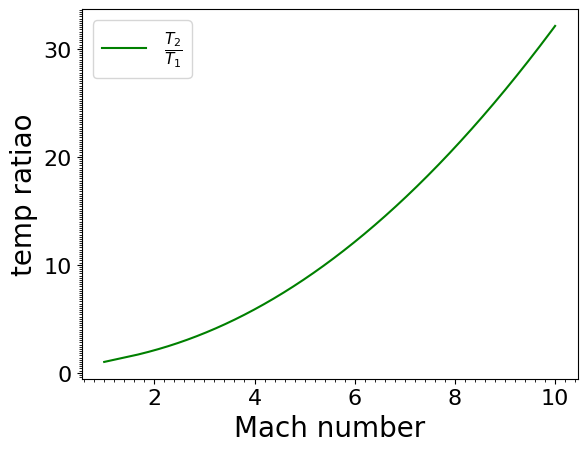

In [ ]:
plt.plot(M_1, T_r, "g", label = r"$\frac{T_2}{T_1}$")
plt.xlabel("Mach number", fontsize=20)
plt.ylabel("temp ratiao", fontsize=20)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
ax = plt.gca()
from matplotlib.ticker import MultipleLocator
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(0.2))
plt.legend(fontsize=16)
plt.legend(fontsize=16)
plt.show()

Text(0, 0.5, 'T_2')

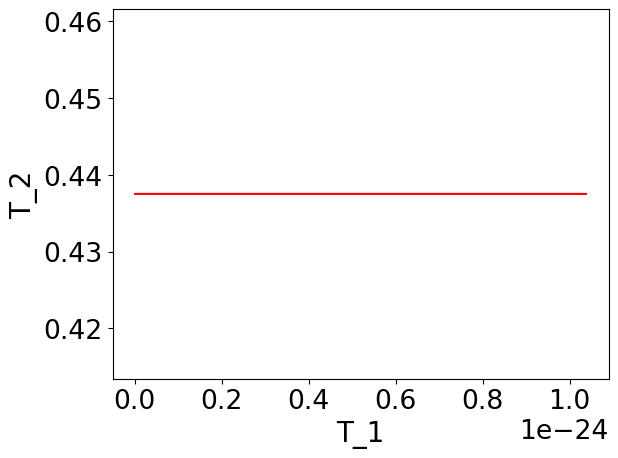

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
M_1 = 2
T_1 = 10**5
rho_1 = mH* (mu) * 10 ** np.linspace(-3, 0, 10000)
u_r, rho_r, T_r = shock_tran(M_1, rho_1, T_1, 1 * 10**-27)
# print(T_r, rho_r)
plt.plot(rho_1 , rho_r, "r")
plt.xlabel("T_1", fontsize=20)
plt.ylabel("T_2", fontsize=20)

[2.078125 2.078125 2.078125 ... 2.078125 2.078125 2.078125] [0.4375 0.4375 0.4375 ... 0.4375 0.4375 0.4375]


Text(0, 0.5, 'T_2')

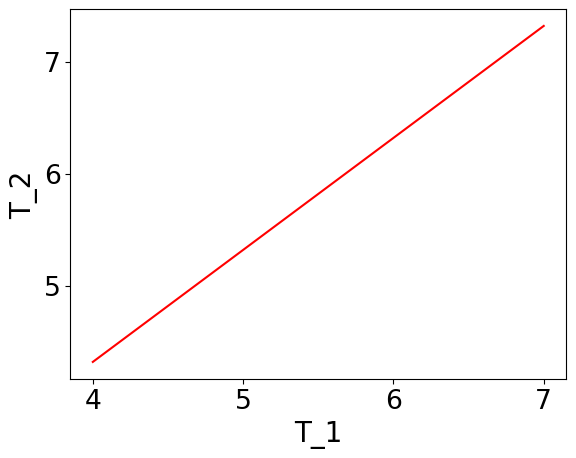

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
M_1 = 2
T_1 = np.linspace(4, 7, 10000)
u_r, rho_r, T_r = shock_tran(M_1, rho_1, 10**T_1, 1 * 10**-27)
print(T_r, rho_r)
plt.plot(T_1, np.log10(T_r*10**T_1), "r")
plt.xlabel("T_1", fontsize=20)
plt.ylabel("T_2", fontsize=20)

In [ ]:
"""
set up
"""
import h5py
from scipy import interpolate
Cooling_File = "z_0.000.hdf5" ### From Wiersma et al. (2009) appropriate for z=0 UVB
f = h5py.File(Cooling_File, 'r')
i_X_He = -3
Metal_free   = f.get('Metal_free')
Total_Metals = f.get('Total_Metals')
log_Tbins    = np.array(np.log10(Metal_free['Temperature_bins']))
log_nHbins   = np.array(np.log10(Metal_free['Hydrogen_density_bins']))
Cooling_Metal_free   = np.array(Metal_free['Net_Cooling'])[i_X_He] ##### what Helium_mass_fraction to use    Total_Metals = f.get('Total_Metals')
Cooling_Total_Metals = np.array(Total_Metals['Net_cooling'])
HHeCooling           = interpolate.RectBivariateSpline(log_Tbins,log_nHbins, Cooling_Metal_free)
ZCooling             = interpolate.RectBivariateSpline(log_Tbins,log_nHbins, Cooling_Total_Metals)
Zs          = np.logspace(-2,1,31)
f.close()
Lambda_tab  = np.array([[[HHeCooling.ev(lT,ln)+Z*ZCooling.ev(lT,ln) for Z in Zs] for lT in log_Tbins] for ln in log_nHbins])
# cooling time is dependent on initial temp and the number density.
Lambda_z0 = interpolate.RegularGridInterpolator((log_nHbins,log_Tbins,Zs), Lambda_tab, bounds_error=False, fill_value=-1e-30)
# why there is out put of nan: is there anything wrong with the interpolation.

In [ ]:
"""
function of cooling function
"""
def tcool_P(T,n, metallicity):
  """
  cooling time function
  T in units of K
  P in units of K * cm **-3
  metallicity in units of solar metallicity
  returning time is log10(s)
  """
  T = np.where(T>10**8.98, 10**8.98, T)
  T = np.where(T<10**2, 10**2, T)
  nH_actual = np.clip(n*(mu/muH), None, 1)
  # n here is the total number density as well, but we convert total number density to hydrogen number density
  nH = np.where(nH_actual>100, 100, nH_actual)
  nH = np.where(nH<10**-8, 10**-8, nH)
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


In [ ]:
print(tcool_P(10**(6.9), 10**(-3.45), 0.2))

18.253598586689407


/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


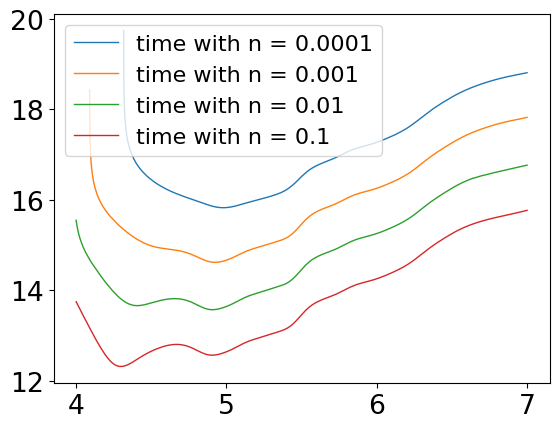

In [ ]:
n_range = np.array((1e-4, 1e-3, 1e-2, 0.1 ))
for n_i in n_range:
  m = mH* mu
  T_1 = np.linspace(4, 7, 10000)
  metallicity = 0.3
  M_1 = 3
  y = tcool_P(10**T_1, n_i, metallicity)
  plt.plot(T_1, (y), linewidth=1, label = f"time with n = {n_i}")

plt.legend(fontsize=16)


All questions come to one question: how to calculate the cooling time, and whether the mass of the particles and the number desity of the particles can affect the cooling time significantly.


/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


13.86398843962795
[        nan         nan         nan ... 17.96105425 17.96108691
 17.96111956]


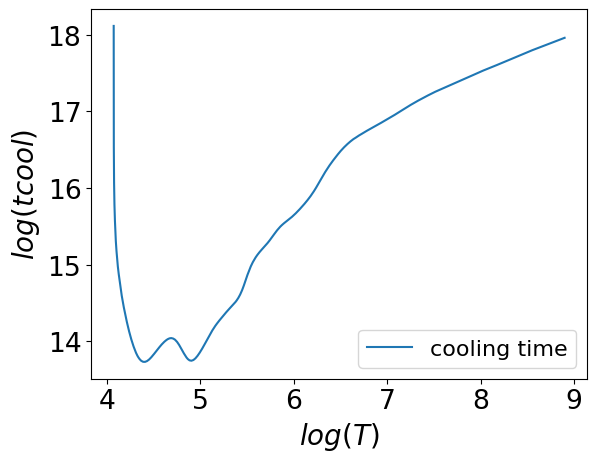

In [ ]:
"""
test code
Cooling time for metality is approximately 0
"""
# defne all the constant at the beginning to make everthing clearer and shorter
T = np.linspace(2, 8.9, 100000)
n = 0.01
metallicity = 0.1
tcool = tcool_P(10**T,n, metallicity)
plt.xlabel(r"$log(T)$", fontsize=20)
plt.ylabel(r"$log(tcool)$", fontsize=20)
plt.plot(T, tcool, label = "cooling time")
plt.legend(fontsize=16)
print(tcool_P(10**(5), 1e-2, metallicity))
print(tcool)

In [ ]:
# Why we only consider hydrogen in the universe: most of the particals are H？

def tcool_shock(M_1, T_1, n_1, m, metallicity):
  """
  M_1 has no unit
  T_1 in unit of k
  rho_1 in unit of kg *cm** -3
  """
  rho_1 = n_1 * m
  u_r, rho_r, T_r = shock_tran(M_1, rho_1, T_1, m)
  T_2 = T_r * T_1
  # the mass above is the average total mass, and the number density above is the total number density
  n_2 = n_1 * rho_r
  tcool1 = tcool_P(T_1, n_1, metallicity)
  tcool2 = tcool_P(T_2, n_2, metallicity)
  return T_2, tcool1, tcool2

In [ ]:
M_1 = 2
T_1 = np.linspace(4, 8, 10000)
n_1 = 0.01
metallicity = 0.1
T_2, tcool1, tcool2 = tcool_shock(M_1, 10**T_1, n_1, mH* (mu), metallicity)
print(tcool1[8000], tcool2[8000])

17.04685228417627 17.615995525998496


/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


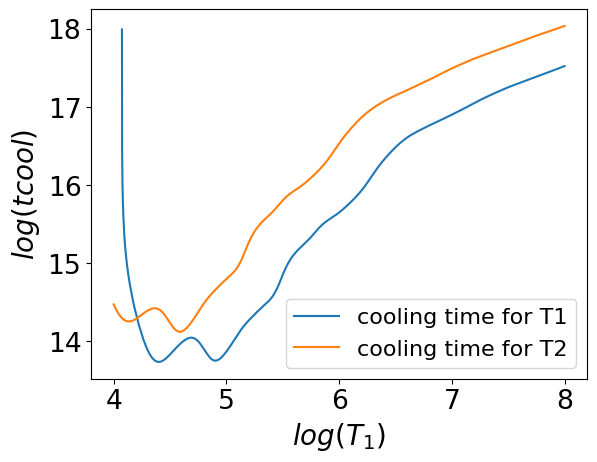

In [ ]:
plt.xlabel(r"$log(T_1)$", fontsize=20)
plt.ylabel(r"$log(tcool)$", fontsize=20)
plt.plot(T_1, tcool1, label = "cooling time for T1")
plt.plot(T_1, tcool2, label = "cooling time for T2")
plt.legend(fontsize=16)

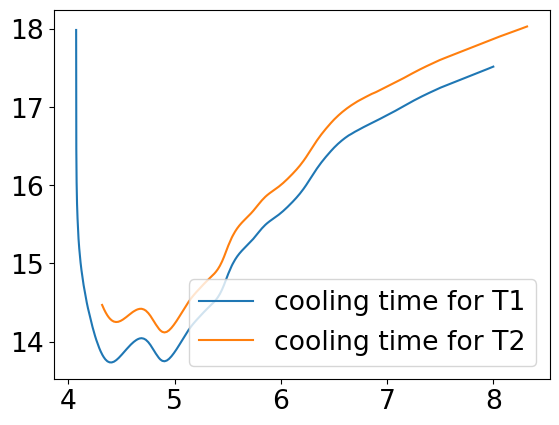

In [ ]:
# Does not reveal too much imformation
plt.plot(T_1, tcool1, label = "cooling time for T1")
plt.plot(np.log10(T_2), tcool2, label = "cooling time for T2")
plt.legend()

In [ ]:
diff = tcool2 - tcool1
ind = np.where(diff<0)[0][0]
print(T_1[ind], tcool1[ind])

4.073207320732073 17.988835584797396


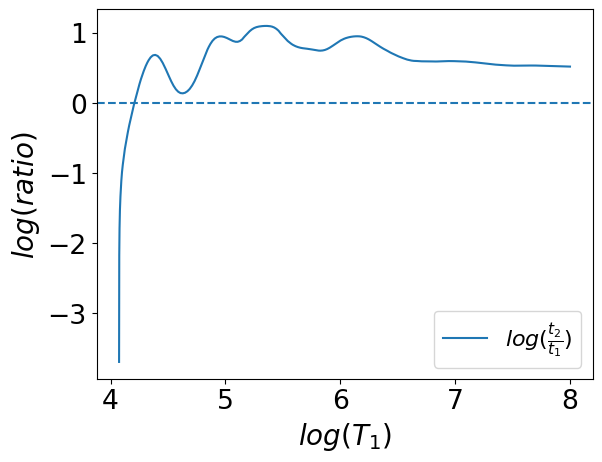

In [ ]:
from matplotlib.lines import lineStyles
plt.plot(T_1, diff, label = r"$log(\frac{t_2}{t_1})$")
plt.xlabel(r"$log(T_1)$", fontsize=20)
plt.ylabel(r"$log(ratio)$", fontsize=20)
plt.axhline(y = 0, linestyle = "--")
plt.legend(fontsize=16)

/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


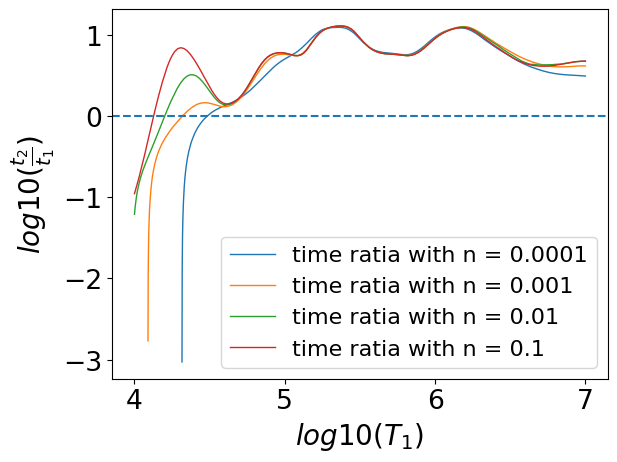

In [ ]:
n_range = np.array((1e-4, 1e-3, 1e-2, 0.1 ))
for n_i in n_range:
  m = mH* (mu)
  T_1 = np.linspace(4, 7, 10000)
  metallicity = 0.3
  M_1 = 2
  T_2, tcool1, tcool2 = tcool_shock(M_1, 10**T_1, n_i, m, metallicity)
  diff = tcool2 - tcool1
  plt.plot(T_1, diff, linewidth=1, label = f"time ratia with n = {n_i}")
plt.xlabel(r"$log10(T_1)$", fontsize=20)
plt.ylabel(r"$log10(\frac{t_2}{t_1})$", fontsize=20)
plt.axhline(y= 0, linestyle = "--")
plt.legend(fontsize=16)


/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


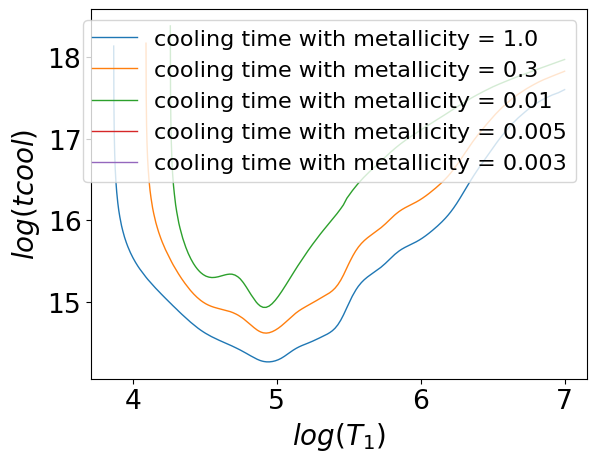

In [ ]:
metallicity_range = np.array((1, 0.3, 0.01, 0.005, 0.003 ))
for metal_i in metallicity_range:
  m = mH* (mu)
  T_1 = np.linspace(2, 7, 10000)
  M = 3
  n = 1e-3
  tcool_metal = tcool_P(10**T_1, n, metal_i)
  plt.plot(T_1, tcool_metal, linewidth=1, label = f"cooling time with metallicity = {metal_i}")
plt.xlabel(r"$log(T_1)$", fontsize=20)
plt.ylabel(r"$log(tcool)$", fontsize=20)
#plt.axhline(y= log_tH, linestyle = "--")
plt.legend(fontsize=16)

/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


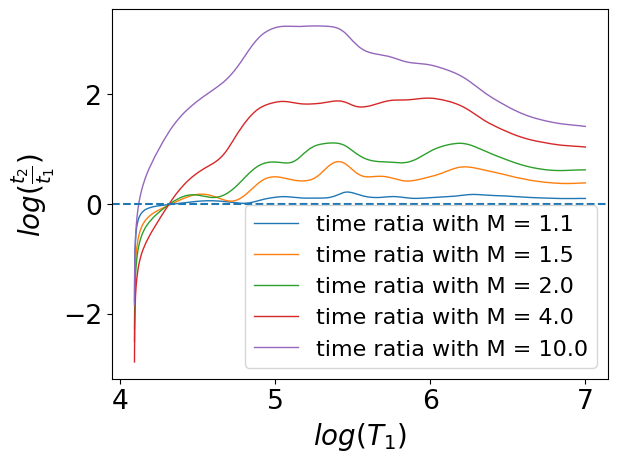

In [ ]:
M_range = np.array((1.1, 1.5, 2, 4, 10 ))
for M_i in M_range:
  m = mH* (mu)
  T_1 = np.linspace(2, 7, 10000)
  metallicity = 0.3
  n = 1e-3
  T_2, tcool1, tcool2 = tcool_shock(M_i, 10**T_1, n, m, metallicity)
  diff = tcool2 - tcool1
  plt.plot(T_1, diff, linewidth=1, label = f"time ratia with M = {M_i}")
plt.xlabel(r"$log(T_1)$", fontsize=20)
plt.ylabel(r"$log(\frac{t_2}{t_1})$", fontsize=20)
plt.axhline(y= 0, linestyle = "--")
plt.legend(fontsize=16)

In [ ]:
"""
cooling time diff
"""
def time_diff(M_1, T_1, n_1, m, metallicity):
  """
  M_1 has no unit
  T_1 in unit of k
  rho_1 in unit of kg *cm** -3
  """
  rho_1 = n_1 * m
  u_r, rho_r, T_r = shock_tran(M_1, rho_1, T_1, m)
  T_2 = T_r * T_1
  n_2 = n_1 * ((gamma+1) * M_1**2)/((gamma - 1) * M_1**2 + 2)
  tcool1 = tcool_P(T_1, n_1, metallicity)
  tcool2 = tcool_P(T_2, n_2, metallicity)
  diff = tcool2 - tcool1
  return diff

**Contour of Changing March number**:

---



In [ ]:
"""Plot of tcool varying March number"""
import numpy as np

T_range = np.linspace(4, 7, 5000)
n = 1e-4
metallicity = 0.3
data = {}
time_range = np.array((14, 15, 16, 17, 16.5))
for ti_val in time_range:
  pairs_M = []

  tcool_vals = tcool_P(10**T_range, n, metallicity)

  mask = (
        (tcool_vals - ti_val > np.log10(0.98)) &
        (tcool_vals - ti_val < np.log10(1.02))
      )

  t_col = T_range[mask]
  data[ti_val] = [] # Use ti_val as the key for the dictionary
  if t_col.size > 0:
        pairs_M.extend(list(t_col)) # Correctly extend with elements of t_col
        data[ti_val].append(pairs_M[0])
        data[ti_val].append(pairs_M[-1])
"""Note that the line at 1e17 is close to hubble time, but is not exactly equal to hubble time"""

/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


'Note that the line at 1e17 is close to hubble time, but is not exactly equal to hubble time'

In [ ]:
print(data[17])

[np.float64(4.370274054810962), np.float64(5.7715543108621725)]


/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))
/tmp/ipykernel_655/3267199576.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=12, loc='lower right')


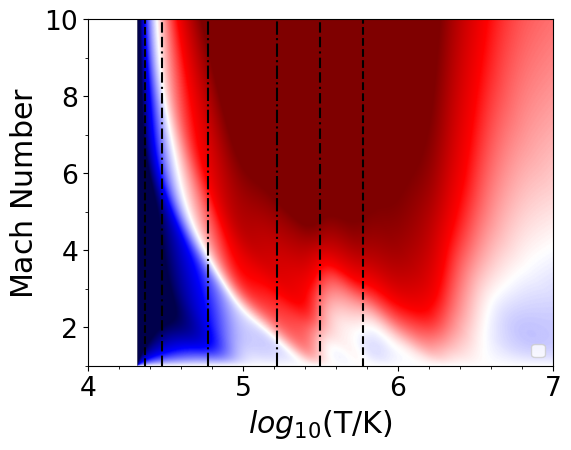

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Create 1D coordinate arrays
M_range = np.linspace(1, 10, 1000)
T_range = np.linspace(4, 7, 1000)
n = 1e-4
metallicity = 0.3
# Create coordinate grid
T , M= np.meshgrid(T_range, M_range)
Z = time_diff(M, 10**T, n, mH* (mu), metallicity)
A = np.max(np.abs(Z))
# Plot heatmap
fig = plt.figure(figsize=(6, 4.5))
scale = 6 / 2.5
plt.rcParams.update({
    "axes.titlesize":  9 * scale,
    "axes.labelsize":  9 * scale,
    "xtick.labelsize": 8 * scale,
    "ytick.labelsize": 8 * scale,
    "legend.fontsize": 8 * scale,
})
plt.imshow(
    Z,
    extent=[T_range.min(), T_range.max(), M_range.min(), M_range.max()],
    origin='lower',
    aspect='auto',
    cmap='seismic', # diverging colormap
    vmin=-1,
    vmax=1
)
T_7_0 = data[17][0]
T_7_1 = data[17][1]
T_6_0 = data[16][0]
T_6_1 = data[16][1]
T_65_0 = data[16.5][0]
T_65_1 = data[16.5][1]
# T_5_0 = data[15][0]
# T_5_1 = data[15][1]
#T_4_0 = data[14][0]
#T_4_1 = data[14][1]
plt.axvline(x = T_7_0, color =  "black", linestyle = "--") # label = r"$t_{cool} = 10^{17}$")
plt.axvline(x = T_7_1, color =  "black", linestyle = "--")
plt.axvline(x = T_6_0, color =  "black", linestyle = "-.") # , label = r"$t_{cool} = 10^{16}$")
plt.axvline(x = T_6_1, color =  "black", linestyle = "-." )
#plt.axvline(x = T_5_0, color =  "black", linestyle=(0, (5, 2, 5, 2, 1, 2)), label = r"$t_{cool} = 10^{15}$")
#plt.axvline(x = T_5_1, color =  "black", linestyle=(0, (5, 2, 5, 2, 1, 2)))
#plt.axvline(x = T_4_0, color =  "black", linestyle=(0, (5, 2, 5, 2, 5, 2, 1, 2)), label = r"t = $10^{14}$")
#plt.axvline(x = T_4_1, color =  "black", linestyle=(0, (5, 2, 5, 2, 5, 2, 1, 2)), label = r"t = $10^{14}$")
plt.axvline(x = T_65_0, color =  "black", linestyle=(0, (5, 2, 5, 2, 1, 2))) # , label = r"$t_{cool} = 10^{16.5}$")
plt.axvline(x = T_65_1, color =  "black", linestyle=(0, (5, 2, 5, 2, 1, 2)))
# plt.colorbar(label=r"$log(\frac{t_2}{t_1})$")
plt.xlabel(r"$log_{10}(\mathrm{T}/\mathrm{K})$")
plt.ylabel(r"$\mathrm{Mach \ Number}$")
ax = plt.gca()
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(1))
# plt.title("Cooling time with varying Mach & T")
plt.legend(fontsize=12, loc='lower right')
plt.show()

# There is no value for t = 1e14 at density of 1e-3
# title n, Metal
# temp of halo and mass

**Contour of Changing density**

---



In [ ]:
"""
plot of tcool = t_H varying n
"""
import numpy as np

T_range = np.linspace(4, 7, 5000)
n_range = np.linspace(-6, 0, 5000)

metallicity = 0.3
t_H = 4.4e17
log_tH = np.log10(t_H)

pairs_n = []

for ti in T_range:
    tcool_vals = tcool_P(10**ti, 10**n_range, metallicity)

    mask = (
        (tcool_vals - log_tH >= np.log10(0.999)) &
        (tcool_vals - log_tH < np.log10(1.001))
    )

    n_col = n_range[mask]

    if n_col.size > 0:
        pairs_n.extend([(ti, ni) for ni in n_col])
T_n_H = [p[0] for p in pairs_n]
n_H = [p[1] for p in pairs_n]

/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


In [ ]:
from scipy.interpolate import interp1d
bottom_func = interp1d(T_n_H, n_H, kind = 'cubic', fill_value="extrapolate")

In [ ]:
from scipy.optimize import root_scalar
t_range = np.array((1e16, 10**(16.5)))
T_range = np.linspace(4, 7, 2000)
metallicity = 0.3
data = {}
for ti in t_range:
    data[ti] = []
    for Ti in T_range:
        def tcool_midel(x):
          return tcool_P(10**Ti, 10**x, metallicity) - np.log10(ti)
        if tcool_midel(bottom_func(Ti))*tcool_midel(0) <= 0:
          solution = root_scalar(tcool_midel, bracket = [bottom_func(Ti), 0], method='brentq')
          data[ti].append((Ti, solution.root))
T0, n_0 = zip(*data[1e16])
T2, n_2 = zip(*data[10**(16.5)])

/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


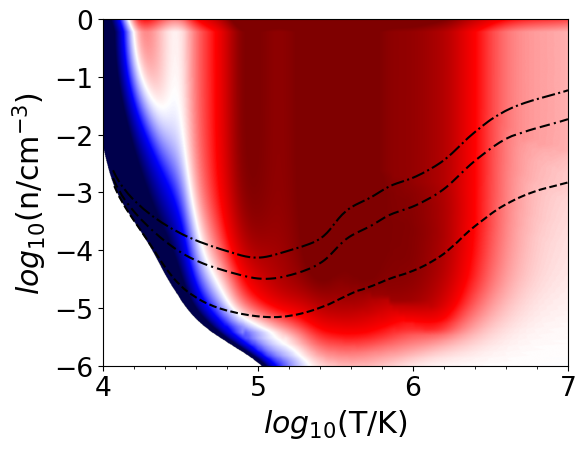

In [ ]:
# Create 1D coordinate arrays
"""
black dash line
"""
import matplotlib.colors as mcolors
n_range = np.linspace(-6, 0, 1000)
T_range = np.linspace(4, 7, 1000)
M_1 = 5
metallicity = 0.3
# Create coordinate grid
T , N= np.meshgrid(T_range, 10**n_range)
Z = time_diff(M_1, 10**T, N, mH* (mu), metallicity)
A = np.max(np.abs(Z))
# Plot heatmap
fig = plt.figure(figsize=(6, 4.5))
plt.rcParams.update({
    "axes.titlesize":  9 * scale,
    "axes.labelsize":  9 * scale,
    "xtick.labelsize": 8 * scale,
    "ytick.labelsize": 8 * scale,
    "legend.fontsize": 8 * scale,
})
plt.imshow(
    Z,
    extent=[T_range.min(), T_range.max(), n_range.min(), n_range.max()],
    origin='lower',
    aspect='auto',
    cmap= 'seismic', # diverging colormap
    vmin=-1,
    vmax=1
)
# plt.colorbar(label=r"$log(\frac{t_2}{t_1})$")
plt.plot(T_n_H, n_H, "black", linestyle = "--") # , label = r"$t_{cool} = 10^{17}$")
plt.plot(T0, n_0, "black", linestyle = "-.")# , label = r"$t_{cool} = 10^{16}$")
# plt.plot(T1, n_1, "black", linestyle=(0, (5, 2, 5, 2, 1, 2)), label = r"$t_{cool} = 10^{15}$")
plt.plot(T2, n_2, "black", linestyle=(0, (5, 2, 5, 2, 1, 2)))# , label = r"$t_{cool} = 10^{14}$")
plt.xlabel(r"$log_{10}(\mathrm{T}/\mathrm{K})$")
plt.ylabel(r"$log_{10}(\mathrm{n}/\mathrm{cm}^{-3})$")
ax = plt.gca()
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(1))
# plt.title("Cooling time with varying n & T")
# plt.legend(fontsize=12, loc='lower right')
plt.show()

**Contour of Changing matallicity**

---

In [ ]:
'''
Plot of tcool = t_H varying metallicity
'''
import numpy as np

T_range = np.linspace(4, 7, 5000)
m_range = np.linspace(-2, 0, 5000)

n = 1e-4
t_H = 1e17
log_tH = np.log10(t_H)

pairs_m = []

for ti in T_range:
    tcool_vals = tcool_P(10**ti, n, 10**m_range)

    mask = (
        (tcool_vals - log_tH >= np.log10(0.999)) &
        (tcool_vals - log_tH <= np.log10(1.001))
    )

    m_col = m_range[mask]

    if m_col.size > 0:
        pairs_m.extend([(ti, Mi) for Mi in m_col])
T_m = [p[0] for p in pairs_m]
m = [10**p[1] for p in pairs_m]

/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


In [ ]:
from scipy.interpolate import interp1d
import numpy as np

# Ensure T_m and m are numpy arrays for consistent behavior
T_m_arr = np.array(T_m)
m_arr = np.array(m)

# Combine T_m_arr and m_arr into a 2D array
combined_data = np.column_stack((T_m_arr, m_arr))

# Sort the combined data by the first column (T_m_arr values)
sorted_combined_data = combined_data[combined_data[:, 0].argsort()]

# Extract unique T_m_arr values and their corresponding m_arr values
# np.unique with return_index will give the unique values and the indices of their first occurrence
unique_T_m_arr, unique_indices = np.unique(sorted_combined_data[:, 0], return_index=True)
unique_m_arr = sorted_combined_data[unique_indices, 1]

bottom_func_2 = interp1d(unique_T_m_arr, unique_m_arr, kind='linear', fill_value="extrapolate")

In [ ]:
from scipy.optimize import root_scalar
t_range = np.array((10**(16), 10**(16.5)))
T_range = np.linspace(4, 7, 2000)
n = 1e-4
data = {}
for ti in t_range:
    data[ti] = []
    for Ti in T_range:
        def tcool_midel(x):
          return tcool_P(10**Ti, n, x) - np.log10(ti)
        if tcool_midel(bottom_func_2(Ti))*tcool_midel(1) <= 0:
          solution = root_scalar(tcool_midel, bracket = [bottom_func_2(Ti), 1], method='brentq')
          data[ti].append((Ti, solution.root))
T0, m_0 = zip(*data[10**(16)])
T1, m_1 = zip(*data[10**(16.5)])
# T2, m_2 = zip(*data[1e14])
# Also there is no value for t = 1e14

/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


/tmp/ipykernel_655/758324487.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


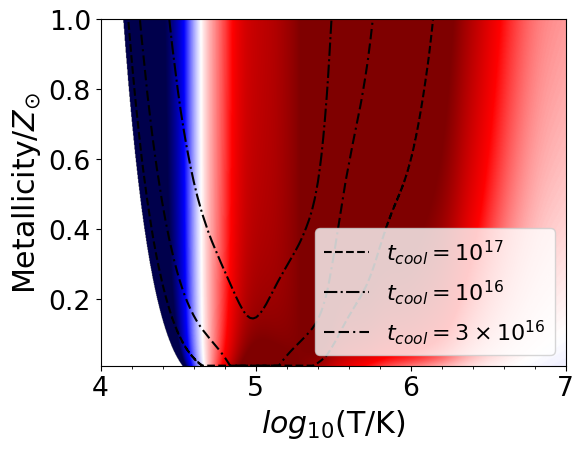

In [ ]:
# Create 1D coordinate arrays
"""
time to 10e10, 10e9 years
"""
import matplotlib.colors as mcolors
Metal_range = np.linspace(0.01, 1, 1000)
T_range = np.linspace(4, 7, 1000)
M_1 = 5
n = 1e-4
# Create coordinate grid
T , Metallicity= np.meshgrid(T_range, Metal_range)
Z = time_diff(M_1, 10**T, n, mH* (mu), Metallicity)
A = np.max(np.abs(Z))
# Plot heatmap
fig = plt.figure(figsize=(6, 4.5))
plt.rcParams.update({
    "axes.titlesize":  9 * scale,
    "axes.labelsize":  9 * scale,
    "xtick.labelsize": 8 * scale,
    "ytick.labelsize": 8 * scale,
    "legend.fontsize": 8 * scale,
})
plt.imshow(
    Z,
    extent=[T_range.min(), T_range.max(), Metal_range.min(), Metal_range.max()],
    origin='lower',
    aspect='auto',
    cmap='seismic', # diverging colormap
    vmin=-1,
    vmax=1
)

plt.plot(T_m_arr, m_arr, "black", linestyle = "--", label = r"$t_{cool} = 10^{17}$")
plt.plot(T0, m_0, "black", linestyle = "-." , label = r"$t_{cool} = 10^{16}$")
plt.plot(T1, m_1, "black", linestyle=(0, (5, 2, 5, 2, 1, 2)), label = r"$t_{cool} = 3 \times 10^{16}$")
# plt.plot(T2, 10**m_2, "black", linestyle=(0, (5, 2, 5, 2, 5, 2, 1, 2)), label = r"t = $10^{14}$")
# plt.colorbar(label=r"$log(\frac{t_{2}}{t_{1}})$")
plt.xlabel(r"$log_{10}(\mathrm{T}/\mathrm{K})$")
plt.ylabel(r"$\mathrm{Metallicity}$/$Z_{\odot}$")
ax = plt.gca()
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(1))
# plt.title("Cooling time with varying Metallicity & T")
plt.legend(fontsize=16, loc='lower right')
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


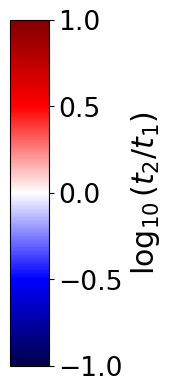

In [ ]:
import matplotlib as mpl

fig, cax = plt.subplots(figsize=(.5, 4.5), constrained_layout=True)

norm = mpl.colors.Normalize(vmin=-1, vmax=1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap='seismic')

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(r'$\log_{10}(t_2/t_1)$')
